In [2]:
import numpy as np
import matplotlib.pyplot as plt

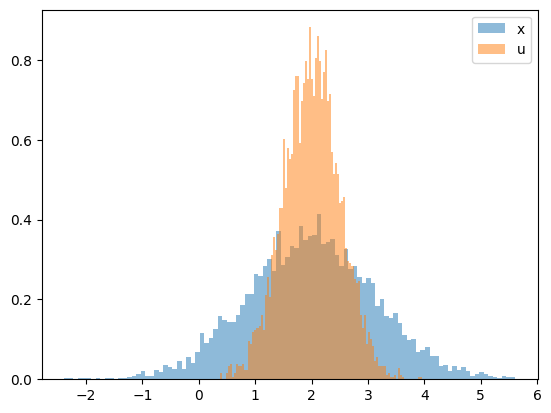

In [3]:
# normal(2, 0.5^2)
np.random.seed(42)
N = 5000
u = np.random.normal(loc=2, scale=0.5, size=(N, 1))
x = u + np.random.randn(N, 1)

plt.hist(x, bins=100, label='x', alpha=0.5, density=True)
plt.hist(u, bins=100, label='u', alpha=0.5, density=True)
plt.legend()
plt.show()

np.save('./normal_u', u)
np.save('./normal_x', x)

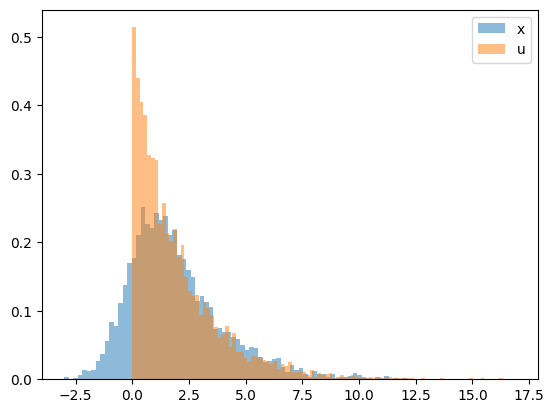

In [2]:
# exp(2)
np.random.seed(42)
N = 5000
u = np.random.exponential(2.0, size = (N, 1))
x = u + np.random.randn(N, 1)

plt.hist(x, bins=100, label='x', alpha=0.5, density=True)
plt.hist(u, bins=100, label='u', alpha=0.5, density=True)
plt.legend()
plt.show()

np.save('./exp_u', u)
np.save('./exp_x', x)

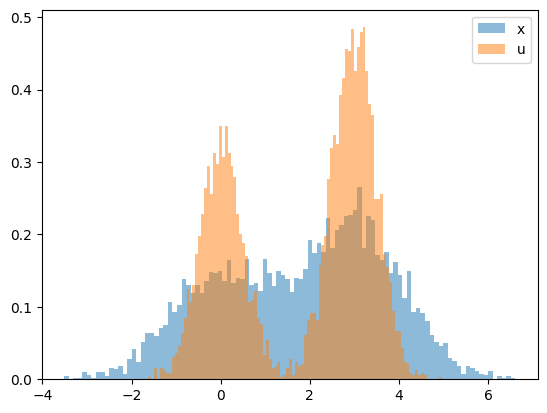

In [3]:
# mix: 0.4 * N(0, 0.5^2) + 0.6 * N(3, 0.5^2)
np.random.seed(42)
N = 5000

u1 = np.random.normal(loc=0, scale=0.5, size=(int(0.4 * N), 1))
u2 = np.random.normal(loc=3, scale=0.5, size=(int(0.6 * N), 1))
u = np.concatenate((u1, u2))
x = u + np.random.randn(N, 1)

plt.hist(x, bins=100, label='x', alpha=0.5, density=True)
plt.hist(u, bins=100, label='u', alpha=0.5, density=True)
plt.legend()
plt.show()

np.save('./mix_u', u)
np.save('./mix_x', x)

For the steps below to obtain the cortex dataset, we recommend creating a new virtual environment. The scvi package is used only for downloading the data and preprocessing, and not for any other part of the workflow.

In [ ]:
# cortex
import scvi
import scanpy as sc

adata = scvi.data.cortex()

def preprocessing(adata, batch_key = None):
    sc.pp.filter_genes(adata, min_counts=3)
    adata.layers["counts"] = adata.X.copy() # preserve counts
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.raw = adata # freeze the state in `.raw`

    sc.pp.highly_variable_genes(
    adata,
    n_top_genes=1200,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key=batch_key
    )

adata = scvi.data.cortex()
preprocessing(adata)
df = adata.layers['counts']
labels = adata.obs['cell_type']

np.save('cortex_x', df)
np.save('cortex_u', labels)